In [1]:
import pandas as pd

df=pd.read_csv(r"C:\Users\User\OneDrive\Desktop\E-Commerce Sales Analytics\data\ecommerce_sales_cleaned.csv")

print(df.columns.tolist())
print(df.head())

['Order_ID', 'Order_Date', 'Customer_ID', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Discount', 'Payment_Method']
  Order_ID  Order_Date Customer_ID        City       Product       Category  \
0  ORD0062  2026-01-01        C096     Negombo       Planner     Stationery   
1  ORD0461  2026-01-01        C127      Jaffna    Marker Set     Stationery   
2  ORD0146  2026-01-01        C057  Kurunegala  Water Bottle  Home & Living   
3  ORD0221  2026-01-01        C131       Kandy       Pen Set     Stationery   
4  ORD0033  2026-01-02        C113     Colombo    Coffee Mug  Home & Living   

   Quantity  Unit_Price  Discount    Payment_Method  
0         2        10.0      0.10       Credit Card  
1         5         7.5      0.15  Cash on Delivery  
2         4        12.0      0.00  Cash on Delivery  
3         3         8.5      0.00    Digital Wallet  
4         1         9.5      0.05    Digital Wallet  


In [2]:
# Calculate Total Revenue

df["Revenue"] = (
    df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])
)

# 1. City Wise Sales
city_sales = df.groupby("City")["Revenue"].sum()

# 2. Top Customer
top_customers = df.groupby("Customer_ID")["Revenue"].sum()

# 3. Payment Method Sales
payment_sales = df.groupby("Payment_Method")["Revenue"].sum()

# 4. Monthly Sales
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Revenue"].sum()

print("All variables created successfully!")

All variables created successfully!


In [3]:
print("Best Performing City:", city_sales.idxmax())
print("Top Customer:", top_customers.idxmax())
print("Highest Revenue Payment Method:", payment_sales.idxmax())
print("Highest Revenue Month:", monthly_sales.idxmax())

Best Performing City: Galle
Top Customer: C147
Highest Revenue Payment Method: Credit Card
Highest Revenue Month: 2026-04


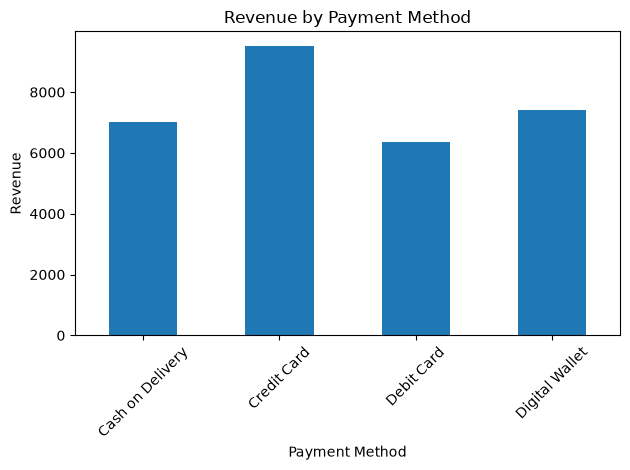

In [4]:
import matplotlib.pyplot as plt 

payment_sales.plot(
    kind="bar",
    title="Revenue by Payment Method",
    xlabel="Payment Method",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
payment_sales = (
    df.groupby("Payment_Method")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

payment_sales

Payment_Method
Credit Card         9521.675
Digital Wallet      7422.875
Cash on Delivery    7032.000
Debit Card          6370.750
Name: Revenue, dtype: float64

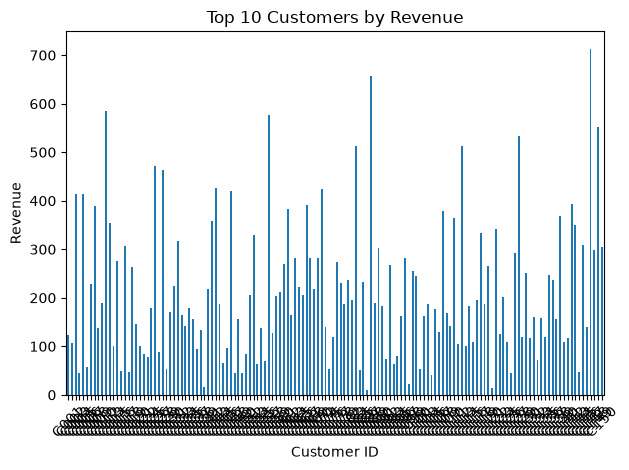

In [6]:
top_customers.plot(
    kind="bar",
    title="Top 10 Customers by Revenue",
    xlabel="Customer ID",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
top_customers = (
    df.groupby("Customer_ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer_ID
C147    713.500
C088    657.400
C012    585.750
C057    577.450
C149    552.700
C128    533.550
C113    513.225
C084    513.150
C026    472.550
C028    463.500
Name: Revenue, dtype: float64

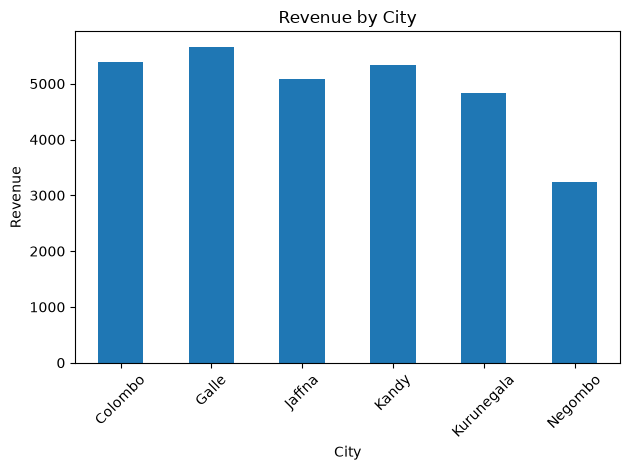

In [8]:
city_sales.plot(
    kind="bar",
    title="Revenue by City",
    xlabel="City",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
city_sales = (
    df.groupby("City")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

city_sales

City
Galle         5655.425
Colombo       5392.450
Kandy         5331.550
Jaffna        5089.775
Kurunegala    4835.675
Negombo       3233.600
Name: Revenue, dtype: float64

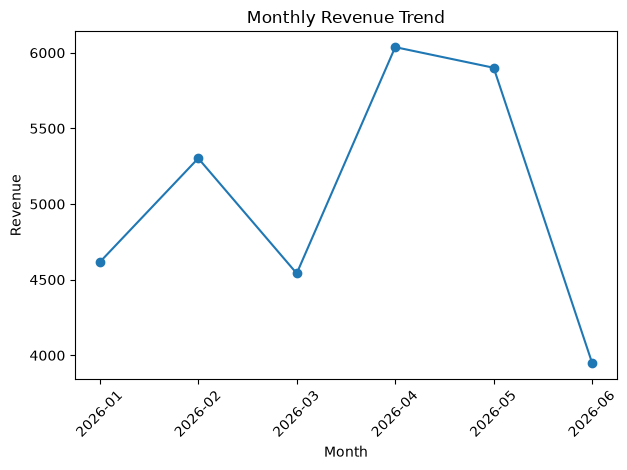

In [10]:
monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Revenue Trend",
    xlabel="Month",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Revenue"].sum()

monthly_sales

Month
2026-01    4616.175
2026-02    5302.375
2026-03    4541.575
2026-04    6037.250
2026-05    5900.850
2026-06    3949.075
Name: Revenue, dtype: float64

In [12]:
total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_items = df["Quantity"].sum()
average_order_value = total_revenue / total_orders

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Items Sold:", total_items)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 30347.3
Total Orders: 500
Total Customers: 142
Total Items Sold: 1477
Average Order Value: 60.69


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/ecommerce_sales_cleaned.csv")
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df.head()

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount,Payment_Method
0,ORD0062,2026-01-01,C096,Negombo,Planner,Stationery,2,10.0,0.10,Credit Card
1,ORD0461,2026-01-01,C127,Jaffna,Marker Set,Stationery,5,7.5,0.15,Cash on Delivery
2,ORD0146,2026-01-01,C057,Kurunegala,Water Bottle,Home & Living,4,12.0,0.00,Cash on Delivery
3,ORD0221,2026-01-01,C131,Kandy,Pen Set,Stationery,3,8.5,0.00,Digital Wallet
4,ORD0033,2026-01-02,C113,Colombo,Coffee Mug,Home & Living,1,9.5,0.05,Digital Wallet


In [14]:
df.head()

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount,Payment_Method
0,ORD0062,2026-01-01,C096,Negombo,Planner,Stationery,2,10.0,0.10,Credit Card
1,ORD0461,2026-01-01,C127,Jaffna,Marker Set,Stationery,5,7.5,0.15,Cash on Delivery
2,ORD0146,2026-01-01,C057,Kurunegala,Water Bottle,Home & Living,4,12.0,0.00,Cash on Delivery
3,ORD0221,2026-01-01,C131,Kandy,Pen Set,Stationery,3,8.5,0.00,Digital Wallet
4,ORD0033,2026-01-02,C113,Colombo,Coffee Mug,Home & Living,1,9.5,0.05,Digital Wallet


In [15]:
# Calculate Total Revenue
df["Revenue"] = (
    df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])
)

# 1. Category Wise Sales
category_sales = df.groupby("Category")["Revenue"].sum()

# 2. City Wise Sales
city_sales = df.groupby("City")["Revenue"].sum()

# 3. Product Wise Sales
top_products = df.groupby("Product")["Revenue"].sum()

# 4. Payment Method Sales
payment_sales = df.groupby("Payment_Method")["Revenue"].sum()

# 5. Top Customer
top_customers = df.groupby("Customer_ID")["Revenue"].sum()

print("All variables created successfully!")

All variables created successfully!


In [16]:
print("Highest Revenue Category:", category_sales.idxmax())
print("Best Performing City:", city_sales.idxmax())
print("Top Selling Product:", top_products.idxmax())
print("Highest Revenue Payment Method:", payment_sales.idxmax())
print("Top Customer:", top_customers.idxmax())

Highest Revenue Category: Electronics
Best Performing City: Galle
Top Selling Product: Mechanical Keyboard
Highest Revenue Payment Method: Credit Card
Top Customer: C147


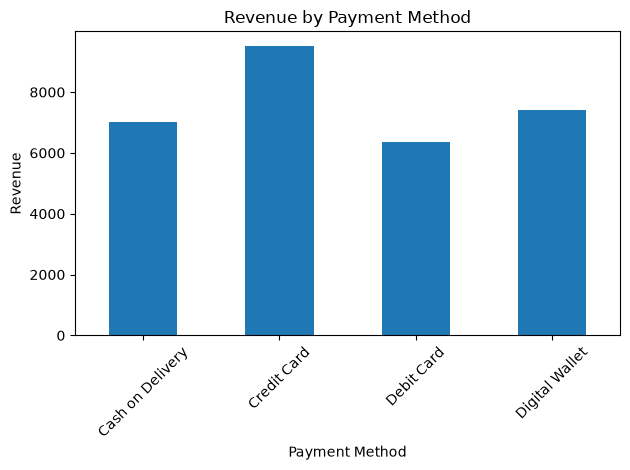

In [17]:
import matplotlib.pyplot as plt

payment_sales.plot(
    kind="bar",
    title="Revenue by Payment Method",
    xlabel="Payment Method",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
payment_sales = (
    df.groupby("Payment_Method")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

payment_sales

Payment_Method
Credit Card         9521.675
Digital Wallet      7422.875
Cash on Delivery    7032.000
Debit Card          6370.750
Name: Revenue, dtype: float64

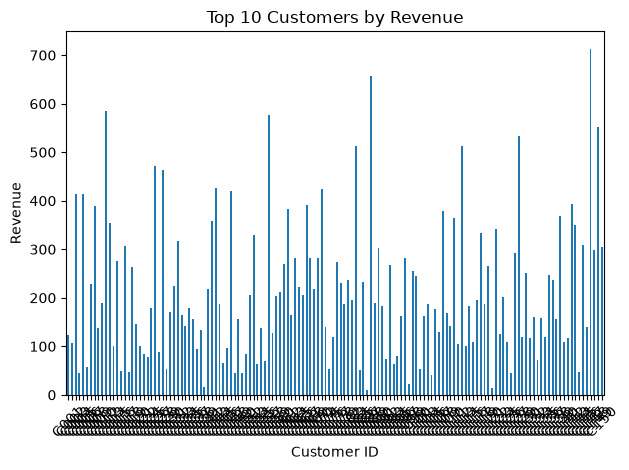

In [19]:
top_customers.plot(
    kind="bar",
    title="Top 10 Customers by Revenue",
    xlabel="Customer ID",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
top_customers = (
    df.groupby("Customer_ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer_ID
C147    713.500
C088    657.400
C012    585.750
C057    577.450
C149    552.700
C128    533.550
C113    513.225
C084    513.150
C026    472.550
C028    463.500
Name: Revenue, dtype: float64

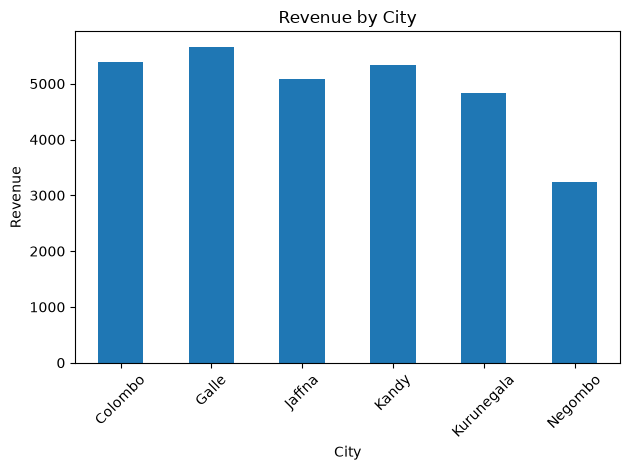

In [21]:
city_sales.plot(
    kind="bar",
    title="Revenue by City",
    xlabel="City",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
city_sales = (
    df.groupby("City")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

city_sales

City
Galle         5655.425
Colombo       5392.450
Kandy         5331.550
Jaffna        5089.775
Kurunegala    4835.675
Negombo       3233.600
Name: Revenue, dtype: float64

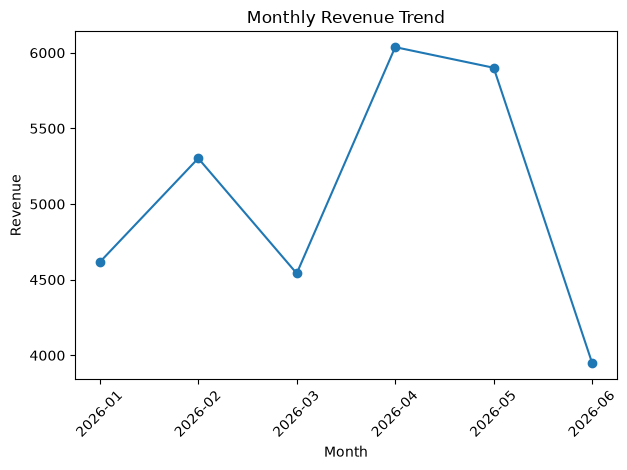

In [23]:
monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Revenue Trend",
    xlabel="Month",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = (
    df.groupby("Month")["Revenue"]
    .sum()
)

monthly_sales

Month
2026-01    4616.175
2026-02    5302.375
2026-03    4541.575
2026-04    6037.250
2026-05    5900.850
2026-06    3949.075
Name: Revenue, dtype: float64

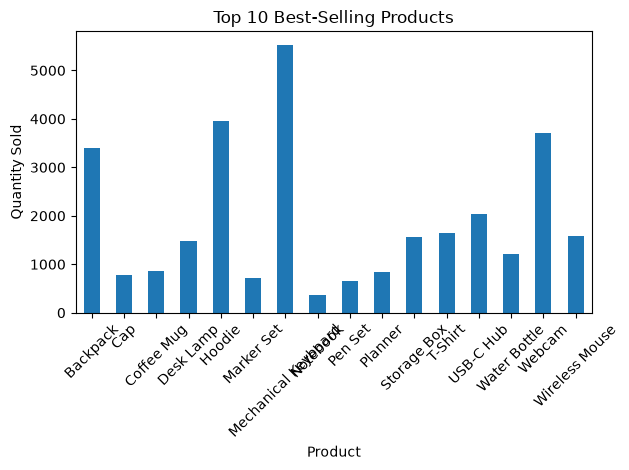

In [25]:
top_products.plot(
    kind="bar",
    title="Top 10 Best-Selling Products",
    xlabel="Product",
    ylabel="Quantity Sold"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
top_products = (
    df.groupby("Product")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product
T-Shirt                113
Storage Box            109
Mechanical Keyboard    107
Water Bottle           107
Marker Set             105
Hoodie                 100
Coffee Mug              99
Backpack                97
Planner                 94
Wireless Mouse          93
Name: Quantity, dtype: int64

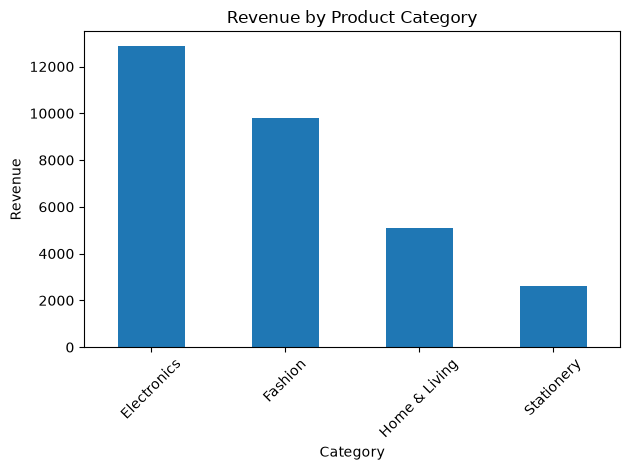

In [27]:
category_sales.plot(
    kind="bar",
    title="Revenue by Product Category",
    xlabel="Category",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
category_sales = (
    df.groupby("Category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

category_sales


Category
Electronics      12862.100
Fashion           9781.200
Home & Living     5102.725
Stationery        2601.275
Name: Revenue, dtype: float64

In [29]:
total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_items = df["Quantity"].sum()
average_order_value = total_revenue / total_orders

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Items Sold:", total_items)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 30347.3
Total Orders: 500
Total Customers: 142
Total Items Sold: 1477
Average Order Value: 60.69


In [30]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        503 non-null    str           
 1   Order_Date      503 non-null    datetime64[us]
 2   Customer_ID     503 non-null    str           
 3   City            495 non-null    str           
 4   Product         503 non-null    str           
 5   Category        503 non-null    str           
 6   Quantity        503 non-null    int64         
 7   Unit_Price      503 non-null    float64       
 8   Discount        503 non-null    float64       
 9   Payment_Method  503 non-null    str           
 10  Revenue         503 non-null    float64       
 11  Month           503 non-null    str           
dtypes: datetime64[us](1), float64(3), int64(1), str(7)
memory usage: 75.3 KB


In [31]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [32]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\User\OneDrive\Desktop\E-Commerce Sales Analytics\data\ecommerce_sales_cleaned.csv")

df.head()

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount,Payment_Method
0,ORD0062,2026-01-01,C096,Negombo,Planner,Stationery,2,10.0,0.10,Credit Card
1,ORD0461,2026-01-01,C127,Jaffna,Marker Set,Stationery,5,7.5,0.15,Cash on Delivery
2,ORD0146,2026-01-01,C057,Kurunegala,Water Bottle,Home & Living,4,12.0,0.00,Cash on Delivery
3,ORD0221,2026-01-01,C131,Kandy,Pen Set,Stationery,3,8.5,0.00,Digital Wallet
4,ORD0033,2026-01-02,C113,Colombo,Coffee Mug,Home & Living,1,9.5,0.05,Digital Wallet
